<a href="https://colab.research.google.com/github/pvgfarias/olist-ecommerce/blob/main/olist_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brazilian E-Commerce (Olist): Deliveries, Reviews and Repeat Customers

Olist connects small and medium Brazilian stores to the large online marketplaces.
This project analyzes a public sample of its data (about 100,000 orders placed by
customers across Brazil between 2016 and 2018) to understand the growth of the business,
where deliveries fell short. We would also like to check whether that affects if customers are likely to order again.

Data: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle)

## Questions

1. How did orders and revenue change month by month?
2. Where are deliveries late, and by how much?
3. Do late deliveries hurt review scores?
4. Do customers come back?

## Key findings

*To be added as each question is answered.*

## Data checks

- 97% of orders (96,478) were delivered. The rest were shipped, canceled, unavailable
  or still processing, which is why 2,965 orders have no delivery date.
  Delivery analysis uses delivered orders only.
- Orders run from September 2016 to October 2018. The first and last months are
  incomplete, so they shouldn't be read as a trend.
- Review scores are always filled in; written comments are optional
  (59% of reviews have no message).

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

path = '/content/drive/MyDrive/olist/'
# parse_dates turns the purchase column into real dates, so we can group by month later
orders = pd.read_csv(path + 'olist_orders_dataset.csv', parse_dates=['order_purchase_timestamp'])
items = pd.read_csv(path + 'olist_order_items_dataset.csv')
customers = pd.read_csv(path + 'olist_customers_dataset.csv')
reviews = pd.read_csv(path + 'olist_order_reviews_dataset.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
# Size of each table: items has more rows than orders because one order can have several products
tables = {'orders': orders, 'items': items, 'customers': customers, 'reviews': reviews}

pd.DataFrame({name: {'rows': df.shape[0], 'columns': df.shape[1]}
              for name, df in tables.items()}).T

,rows,columns
orders,99441,8
items,112650,7
customers,99441,5
reviews,99224,7


# Data checks
Checking columns, missing values and the date range before analysis.

In [8]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [9]:
orders.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [10]:
orders['order_status'].value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [11]:
orders['order_purchase_timestamp'].agg(['min', 'max'])

,order_purchase_timestamp
min,2016-09-04 21:15:19
max,2018-10-17 17:30:18


In [12]:
reviews.isna().sum()

,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0



- 97% of orders (96,478) were delivered. The rest were shipped, canceled, unavailable
  or still processing, which is why 2,965 orders have no delivery date.
  Delivery analysis uses delivered orders only.
- Orders run from September 2016 to October 2018. The first and last months are
  incomplete, so they shouldn't be read as a trend.
- Review scores are always filled in; written comments are optional
  (59% of reviews have no message).

## 1. Monthly orders and revenue.

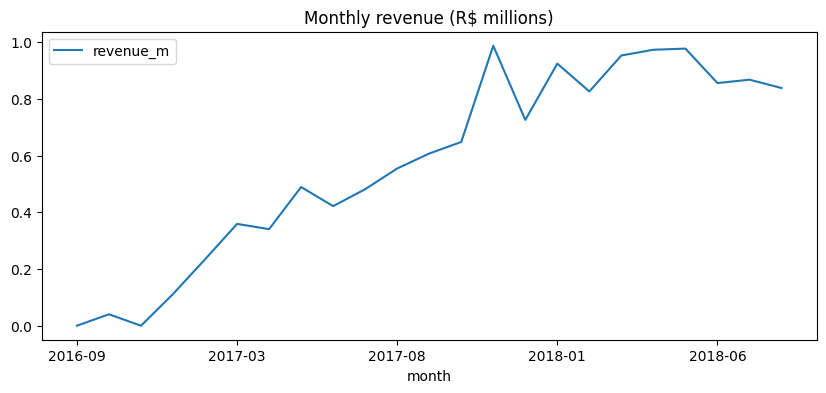

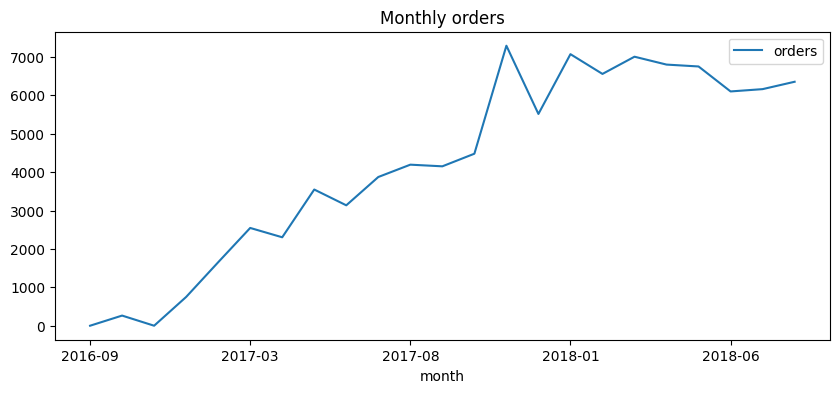

In [24]:
delivered = orders[orders['order_status'] == 'delivered']
df = pd.merge(delivered, items, on='order_id', how='inner')
df['month'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)
monthly = df.groupby(by='month').agg(
    orders = ('order_id', 'nunique'),
    revenue = ('price', 'sum')
).reset_index()

# showing revenue as millions
monthly['revenue_m'] = monthly['revenue'] / 1_000_000

monthly.plot(x='month', y='revenue_m', title='Monthly revenue (R$ millions)', figsize=(10, 4))
monthly.plot(x='month', y='orders', title='Monthly orders', figsize=(10, 4))
plt.show()

**Findings:** The data starts being recorded in 2016, so the jump from 2016 to 2017 does not tell us much yet. However, we can see a steady growth during 2017. In November 2017, there is a peak of about 7300 orders and revenue of about R$1 million, which is when Black Friday happens. In 2018, the orders stop growing at about 6-7k per month. Since we only considered the delivered cases, the data in 2018's last month is incomplete because some orders were probably still being delivered.

*Note: revenue = product price only, excluding freight (freight_value).*